## Q2. Classification on Student Performance Dataset : DT, Logistic Regression, SVM, RF, KNN, AdaBoost, XGBoost

#### RAW Data

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
df=pd.read_csv("student_performance.csv")
print(df.head())

   StudentID  Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  \
0       1001   17       1          1                  3               16   
1       1002   18       1          2                  0               17   
2       1003   15       1          0                  1               13   
3       1004   17       1          0                  3                6   
4       1005   17       0          1                  2                6   

   Absences  Tutoring  ParentalSupport  Extracurricular  Sports  Music  \
0        13         0                2                0       0      0   
1        28         0                2                1       1      1   
2        18         1                4                0       0      0   
3         4         0                3                1       0      0   
4        20         0                4                0       0      0   

   Volunteering       GPA  GradeClass  
0             0  3.158425           1  
1             0  2

## Preprocessing

In [5]:
# Check how many duplicate rows exist
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows (keeping first occurrence)
df = df.drop_duplicates()

Duplicate rows: 0


In [6]:
# Check missing count across rows
print(df.isnull().sum())

# Drop rows where target or key features are missing
df = df.dropna()

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


In [7]:
# remove rows with extreme outliers beyond the 99th percentile
q_high = df['Absences'].quantile(0.99)
df = df[df['Absences'] <= q_high]

In [9]:
# Drop StudentID and GPA before training the classification models
df_clean = df.drop(columns=['StudentID', 'GPA'])



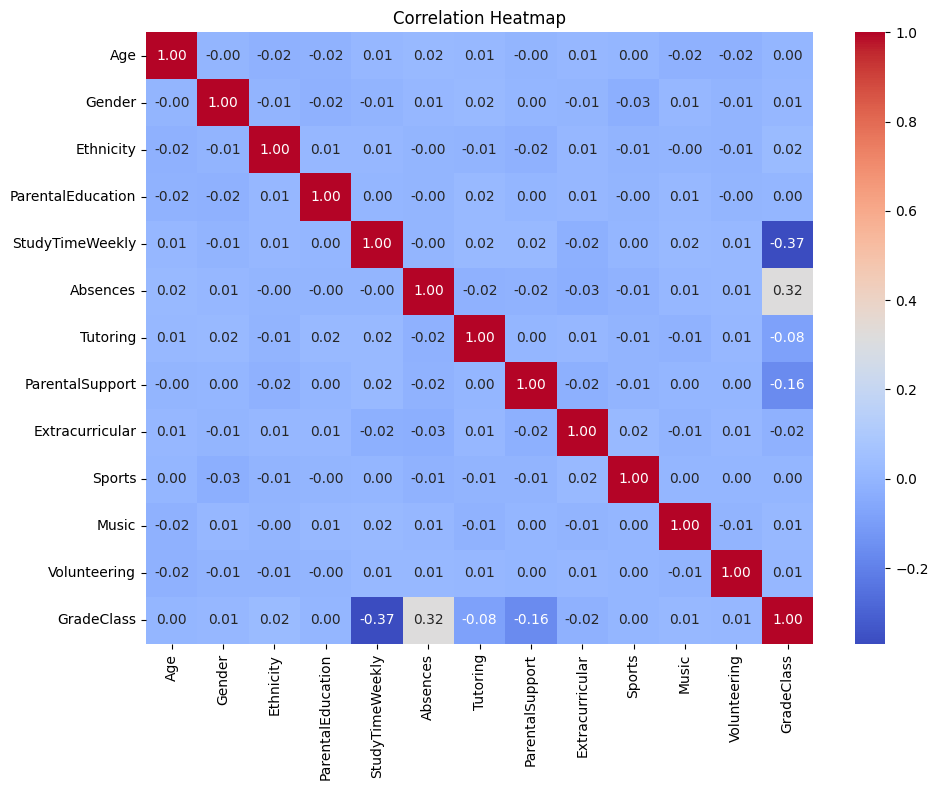

C:\Users\jagat\AppData\Local\Temp\ipykernel_13580\3535131349.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="GradeClass", palette="Set2")


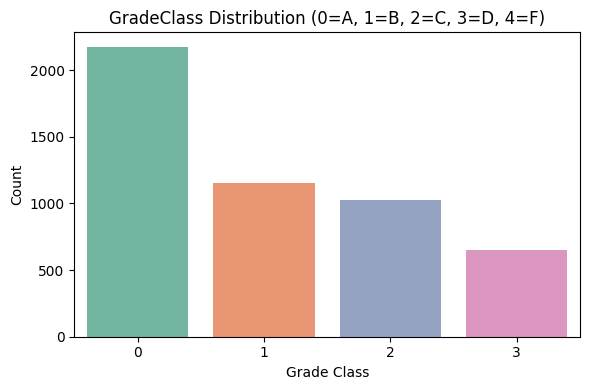

In [20]:
# Standalone Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Target Distribution Plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="GradeClass", palette="Set2")
plt.title("GradeClass Distribution (0=A, 1=B, 2=C, 3=D, 4=F)")
plt.xlabel("Grade Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Train Test

In [10]:
# Separate features and target
X = df_clean.drop(columns=['GradeClass'])
y = df_clean['GradeClass']

In [25]:
print(df_clean.head())

   Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  Absences  \
0   17       1          1                  3               16        13   
1   18       1          2                  0               17        28   
2   15       1          0                  1               13        18   
3   17       1          0                  3                6         4   
4   17       0          1                  2                6        20   

   Tutoring  ParentalSupport  Extracurricular  Sports  Music  Volunteering  \
0         0                2                0       0      0             0   
1         0                2                1       1      1             0   
2         1                4                0       0      0             1   
3         0                3                1       0      0             0   
4         0                4                0       0      0             0   

   GradeClass  
0           1  
1           2  
2           0  
3           1  


In [11]:
from sklearn.model_selection import train_test_split

# 80-20 train-test split with stratification for classification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

### Scaling

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define columns for scaling and encoding
num_features = ['Age', 'StudyTimeWeekly', 'Absences']
cat_features = [col for col in X.columns if col not in num_features]

# Preprocessor: StandardScaler on numerical, OneHotEncoder on categorical
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ]
)

# Fit exclusively on X_train to prevent data leakage
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"X_train shape after preprocessing: {X_train_proc.shape}")
print(f"X_test shape after preprocessing:  {X_test_proc.shape}")

X_train shape after preprocessing: (4000, 20)
X_test shape after preprocessing:  (1000, 20)


## Applying DT, Logistic Regression, SVM, RF, KNN, AdaBoost, XGBoost

In [27]:
# DT
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dt_model = DecisionTreeClassifier(max_depth=5,random_state=42)
dt_model.fit(X_train_proc, y_train)

y_pred = dt_model.predict(X_test_proc)
print("Decision Tree Classifier Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Decision Tree Classifier Accuracy: 0.461
              precision    recall  f1-score   support

           0       0.52      0.84      0.64       421
           1       0.22      0.08      0.11       236
           2       0.31      0.07      0.12       204
           3       0.38      0.53      0.45       139

    accuracy                           0.46      1000
   macro avg       0.36      0.38      0.33      1000
weighted avg       0.39      0.46      0.38      1000



In [28]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42, max_iter=1000, multi_class='multinomial')
lr_model.fit(X_train_proc, y_train)
y_pred = lr_model.predict(X_test_proc)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Logistic Regression Accuracy: 0.473
              precision    recall  f1-score   support

           0       0.53      0.86      0.65       421
           1       0.21      0.04      0.06       236
           2       0.26      0.16      0.20       204
           3       0.47      0.50      0.49       139

    accuracy                           0.47      1000
   macro avg       0.37      0.39      0.35      1000
weighted avg       0.39      0.47      0.40      1000



In [29]:
# SVM Classifier
from sklearn.svm import SVC

svc_model = SVC(random_state=42, kernel='rbf', C=1.0, gamma='scale')
svc_model.fit(X_train_proc, y_train)

y_pred = svc_model.predict(X_test_proc)

print("SVM Classifier Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

SVM Classifier Accuracy: 0.477
              precision    recall  f1-score   support

           0       0.51      0.91      0.65       421
           1       0.31      0.05      0.08       236
           2       0.33      0.10      0.16       204
           3       0.42      0.44      0.43       139

    accuracy                           0.48      1000
   macro avg       0.39      0.38      0.33      1000
weighted avg       0.41      0.48      0.39      1000



In [30]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5, min_samples_split=5, min_samples_leaf=2)
rf_model.fit(X_train_proc, y_train)


y_pred = rf_model.predict(X_test_proc)
print("Random Forest Classifier Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Random Forest Classifier Accuracy: 0.456
              precision    recall  f1-score   support

           0       0.46      0.99      0.63       421
           1       0.00      0.00      0.00       236
           2       0.17      0.02      0.04       204
           3       0.55      0.24      0.34       139

    accuracy                           0.46      1000
   macro avg       0.30      0.31      0.25      1000
weighted avg       0.31      0.46      0.32      1000



In [31]:
## KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_proc, y_train) 

y_pred_knn = knn_model.predict(X_test_proc)  
print("KNN Classifier Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

KNN Classifier Accuracy: 0.428
              precision    recall  f1-score   support

           0       0.52      0.74      0.61       421
           1       0.30      0.24      0.27       236
           2       0.24      0.15      0.19       204
           3       0.35      0.21      0.26       139

    accuracy                           0.43      1000
   macro avg       0.35      0.33      0.33      1000
weighted avg       0.39      0.43      0.39      1000



In [32]:
#AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train_proc, y_train)
y_pred_ada = ada_model.predict(X_test_proc)
print("AdaBoost Classifier Accuracy:", accuracy_score(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada))

AdaBoost Classifier Accuracy: 0.465
              precision    recall  f1-score   support

           0       0.54      0.83      0.66       421
           1       0.25      0.08      0.13       236
           2       0.24      0.10      0.14       204
           3       0.40      0.55      0.46       139

    accuracy                           0.47      1000
   macro avg       0.36      0.39      0.35      1000
weighted avg       0.39      0.47      0.40      1000



In [33]:
# XGboost Classifier
from xgboost import XGBClassifier
xgb_model = XGBClassifier(n_estimators=100, random_state=42, max_depth=5, learning_rate=0.1)
xgb_model.fit(X_train_proc, y_train)
y_pred_xgb = xgb_model.predict(X_test_proc)
print("XGBoost Classifier Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

XGBoost Classifier Accuracy: 0.46
              precision    recall  f1-score   support

           0       0.53      0.82      0.65       421
           1       0.26      0.10      0.15       236
           2       0.28      0.17      0.21       204
           3       0.40      0.42      0.41       139

    accuracy                           0.46      1000
   macro avg       0.37      0.38      0.35      1000
weighted avg       0.40      0.46      0.41      1000



## HyperParmeter tuning

In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, f1_score

In [36]:
# Tuning SVM Classifier with GridSearchCV
svm_param_grid = {'C': [0.1, 1.0, 5.0], 
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf']
}

svm_grid = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=svm_param_grid,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)

svm_grid.fit(X_train_proc, y_train)
best_svm = svm_grid.best_estimator_

print("Best SVM Params:", svm_grid.best_params_)
y_pred_svm = best_svm.predict(X_test_proc)
print("Tuned SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Tuned SVM F1-Score:", f1_score(y_test, y_pred_svm, average='weighted'))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm, zero_division=0))

Best SVM Params: {'C': 5.0, 'gamma': 'scale', 'kernel': 'rbf'}
Tuned SVM Accuracy: 0.455
Tuned SVM F1-Score: 0.41293028759805533

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.79      0.64       421
           1       0.31      0.17      0.22       236
           2       0.25      0.15      0.18       204
           3       0.42      0.37      0.40       139

    accuracy                           0.46      1000
   macro avg       0.38      0.37      0.36      1000
weighted avg       0.41      0.46      0.41      1000



In [38]:
# Tuning Logistic Regression with GridSearchCV
lr_param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'solver': ['lbfgs', 'saga'],
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=1000, multi_class='multinomial'),
    param_grid=lr_param_grid,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
) 

lr_grid.fit(X_train_proc, y_train)
best_lr = lr_grid.best_estimator_

print("Best Logistic Regression Params:", lr_grid.best_params_)
y_pred_lr = best_lr.predict(X_test_proc)
print("Tuned Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Tuned Logistic Regression F1-Score:", f1_score(y_test, y_pred_lr, average='weighted'))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr, zero_division=0))
print("Best Logistic Regression Params:", lr_grid.best_params_)

Best Logistic Regression Params: {'C': 10.0, 'solver': 'saga'}
Tuned Logistic Regression Accuracy: 0.474
Tuned Logistic Regression F1-Score: 0.3994251608132104

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.86      0.65       421
           1       0.21      0.04      0.06       236
           2       0.27      0.16      0.20       204
           3       0.47      0.50      0.49       139

    accuracy                           0.47      1000
   macro avg       0.37      0.39      0.35      1000
weighted avg       0.39      0.47      0.40      1000

Best Logistic Regression Params: {'C': 10.0, 'solver': 'saga'}


In [ ]:
# Tuning AdaBoost Classifier with GridSearchCV
ada_param_grid = {
    'n_estimators': [30, 50, 100],
    'learning_rate': [0.01, 0.1, 1.0]
}

ada_grid = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=ada_param_grid,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)

ada_grid.fit(X_train_proc, y_train)
best_ada = ada_grid.best_estimator_

print("Best AdaBoost Params:", ada_grid.best_params_)
y_pred_ada = best_ada.predict(X_test_proc)
print("Tuned AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Tuned AdaBoost F1-Score:", f1_score(y_test, y_pred_ada, average='weighted'))
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada, zero_division=0))

Best AdaBoost Params: {'learning_rate': 1.0, 'n_estimators': 100}
Tuned AdaBoost Accuracy: 0.465
Tuned AdaBoost F1-Score: 0.3992110417697209

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.83      0.66       421
           1       0.25      0.08      0.13       236
           2       0.24      0.10      0.14       204
           3       0.40      0.55      0.46       139

    accuracy                           0.47      1000
   macro avg       0.36      0.39      0.35      1000
weighted avg       0.39      0.47      0.40      1000



In [40]:
# Tuning Decision Tree Classifier with GridSearchCV
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)

dt_grid.fit(X_train_proc, y_train)
best_dt = dt_grid.best_estimator_

print("Best Decision Tree Params:", dt_grid.best_params_)
y_pred_dt = best_dt.predict(X_test_proc)
print("Tuned Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Tuned Decision Tree F1-Score:", f1_score(y_test, y_pred_dt, average='weighted'))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt, zero_division=0))

Best Decision Tree Params: {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 10}
Tuned Decision Tree Accuracy: 0.407
Tuned Decision Tree F1-Score: 0.39028428685259564

Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.67      0.60       421
           1       0.28      0.25      0.27       236
           2       0.20      0.16      0.18       204
           3       0.32      0.24      0.28       139

    accuracy                           0.41      1000
   macro avg       0.34      0.33      0.33      1000
weighted avg       0.38      0.41      0.39      1000



## Bagging and Boosting

In [41]:
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# -------------------------------------------------------------------------
# 1. BAGGING ALL 7 ALGORITHMS
# -------------------------------------------------------------------------
base_models_for_bagging = {
    "DT": dt_model,
    "LogisticRegression": best_lr,
    "SVM": best_svm,
    "RF": rf_model,
    "KNN": knn_model,
    "AdaBoost": best_ada,
    "XGBoost": xgb_model
}

bagged_models = {}
bagged_probs = []

print("=== 1. BAGGING ALL MODELS ===")
for name, model in base_models_for_bagging.items():
    bag = BaggingClassifier(
        estimator=model,
        n_estimators=10,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    )
    bag.fit(X_train_proc, y_train)
    bagged_models[name] = bag
    
    # Predict and evaluate
    y_pred = bag.predict(X_test_proc)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"Bagged {name:<20} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")
    
    # Store probability distributions for consensus combination
    bagged_probs.append(bag.predict_proba(X_test_proc))

# Combined consensus of ALL bagged models (Averaging predicted probabilities)
combined_bagging_prob = np.mean(bagged_probs, axis=0)
combined_bagging_pred = np.argmax(combined_bagging_prob, axis=1)

print("-" * 50)
print(f"COMBINED BAGGING OF ALL 7: Accuracy = {accuracy_score(y_test, combined_bagging_pred):.4f} | F1 = {f1_score(y_test, combined_bagging_pred, average='weighted'):.4f}")


# -------------------------------------------------------------------------
# 2. BOOSTING ACROSS COMPATIBLE ALGORITHMS
# -------------------------------------------------------------------------
# Note: KNN does not accept sample_weight, so it cannot be boosted via AdaBoost.
base_models_for_boosting = {
    "DT": DecisionTreeClassifier(max_depth=2, random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42),
    "SVM": SVC(probability=True, kernel='linear', random_state=42),
    "RF": RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42)
}

boosted_models = {}
boosted_probs = []

print("\n=== 2. BOOSTING APPLIED ACROSS BASE ALGORITHMS ===")
for name, model in base_models_for_boosting.items():
    boost = AdaBoostClassifier(
        estimator=model,
        n_estimators=30,
        learning_rate=0.1,
        random_state=42
    )
    boost.fit(X_train_proc, y_train)
    boosted_models[name] = boost
    
    y_pred = boost.predict(X_test_proc)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"Boosted {name:<19} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")
    
    boosted_probs.append(boost.predict_proba(X_test_proc))

# Add native gradient boosting (XGBoost) to the boosting consensus pool
boosted_probs.append(xgb_model.predict_proba(X_test_proc))

# Combined consensus of ALL boosted models
combined_boosting_prob = np.mean(boosted_probs, axis=0)
combined_boosting_pred = np.argmax(combined_boosting_prob, axis=1)

print("-" * 50)
print(f"COMBINED BOOSTING OF ALL:   Accuracy = {accuracy_score(y_test, combined_boosting_pred):.4f} | F1 = {f1_score(y_test, combined_boosting_pred, average='weighted'):.4f}")

=== 1. BAGGING ALL MODELS ===
Bagged DT                   | Accuracy: 0.4810 | F1-Score: 0.3870
Bagged LogisticRegression   | Accuracy: 0.4700 | F1-Score: 0.3971
Bagged SVM                  | Accuracy: 0.4650 | F1-Score: 0.3565
Bagged RF                   | Accuracy: 0.4530 | F1-Score: 0.3219
Bagged KNN                  | Accuracy: 0.4190 | F1-Score: 0.3920
Bagged AdaBoost             | Accuracy: 0.4710 | F1-Score: 0.4126
Bagged XGBoost              | Accuracy: 0.4550 | F1-Score: 0.3921
--------------------------------------------------
COMBINED BAGGING OF ALL 7: Accuracy = 0.4830 | F1 = 0.3967

=== 2. BOOSTING APPLIED ACROSS BASE ALGORITHMS ===
Boosted DT                  | Accuracy: 0.4870 | F1-Score: 0.3834
Boosted LogisticRegression  | Accuracy: 0.4370 | F1-Score: 0.2874
Boosted SVM                 | Accuracy: 0.4780 | F1-Score: 0.3366
Boosted RF                  | Accuracy: 0.4640 | F1-Score: 0.3611
--------------------------------------------------
COMBINED BOOSTING OF ALL:   Acc

## Leader Board

In [44]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Dictionary of trained models evaluated on X_test_proc
candidate_models = {
    "Logistic Regression (Tuned)": best_lr,
    "SVM (Tuned)": best_svm,
    "AdaBoost (Tuned)": best_ada,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model,
    "XGBoost": xgb_model
}

# If you kept your ensembles from earlier steps, add them here:
# candidate_models["Weighted Voting"] = voting_clf
# candidate_models["Stacking"] = stacking_clf

results = []

for name, model in candidate_models.items():
    y_pred = model.predict(X_test_proc)
    
    # Calculate OvR ROC-AUC using predicted class probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_proc)
        try:
            auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="weighted")
        except ValueError:
            auc = np.nan
    else:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4),
        "ROC-AUC (OvR)": round(auc, 4) if not np.isnan(auc) else "N/A"
    })

leaderboard_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("=" * 75)
print("CLASSIFICATION PERFORMANCE LEADERBOARD")
print("=" * 75)
print(leaderboard_df.to_string(index=False))

CLASSIFICATION PERFORMANCE LEADERBOARD
                      Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC (OvR)
                SVM (Tuned)     0.455     0.4066   0.455    0.4129         0.6673
                    XGBoost     0.460     0.4006   0.460    0.4061         0.6705
Logistic Regression (Tuned)     0.474     0.3922   0.474    0.3994         0.6890
           AdaBoost (Tuned)     0.465     0.3918   0.465    0.3992         0.6327
                        KNN     0.428     0.3866   0.428    0.3939         0.6211
              Decision Tree     0.461     0.3883   0.461    0.3844         0.6644
              Random Forest     0.456     0.3055   0.456    0.3190         0.6861


## Ensemble Learning

In [46]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report


# STACKING ENSEMBLE (With Balanced Meta-Learner)

stacking_estimators = [
    ('svm', best_svm),
    ('lr', best_lr),
    ('ada', best_ada),
    ('xgb', xgb_model)
]

# The meta-classifier learns the optimal blending of probabilities.
# Setting class_weight='balanced' prevents it from collapsing onto Class 0.
stacking_clf = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000, 
        class_weight='balanced', 
        random_state=42
    ),
    cv=5,
    n_jobs=-1
)

stacking_clf.fit(X_train_proc, y_train)
y_pred_stack = stacking_clf.predict(X_test_proc)

print("=" * 60)
print("STACKING ENSEMBLE (Meta-Learner: Balanced Logistic Regression)")
print("Accuracy:", accuracy_score(y_test, y_pred_stack))
print("F1-Score (Weighted):", f1_score(y_test, y_pred_stack, average='weighted'))
print("\nClassification Report:\n", classification_report(y_test, y_pred_stack, zero_division=0))

STACKING ENSEMBLE (Meta-Learner: Balanced Logistic Regression)
Accuracy: 0.441
F1-Score (Weighted): 0.39880590178448144

Classification Report:
               precision    recall  f1-score   support

           0       0.62      0.64      0.63       421
           1       0.26      0.03      0.05       236
           2       0.24      0.28      0.26       204
           3       0.35      0.76      0.48       139

    accuracy                           0.44      1000
   macro avg       0.37      0.43      0.36      1000
weighted avg       0.42      0.44      0.40      1000

